In [ ]:
# creating csv from phase 2 

# df_cleaned.to_csv(
#     "data_files/diabetic_data_enriched.csv",
#     index=False
# )

Installing the Libraries

In [1]:
%pip install pandas numpy matplotlib seaborn
%pip install seaborn matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


Load the dataset

In [4]:
from pathlib import Path
import pandas as pd

file_path = Path("data_files/diabetic_data_enriched.csv")

# Alternative path 
if not file_path.exists():
    file_path = Path("/mnt/data/diabetic_data_enriched.csv")

df = pd.read_csv(file_path, low_memory=False)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (100114, 50)


,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,...,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,Primary_Diagnosis_Desc
0,2278392,8222157,Caucasian,Female,[0-10),6,25,1,1,NaN,...,No,No,No,No,No,No,No,No,NO,Other
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,NaN,...,Up,No,No,No,No,No,Ch,Yes,>30,Fluid Disorders
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,NaN,...,No,No,No,No,No,No,No,Yes,NO,Other
3,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,NaN,...,Up,No,No,No,No,No,Ch,Yes,NO,Other
4,16680,42519267,Caucasian,Male,[40-50),1,1,7,1,NaN,...,Steady,No,No,No,No,No,Ch,Yes,NO,Other



Column names:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted', 'Primary_Diagnosis_Desc']


Readmission Distribution (Count Plot)

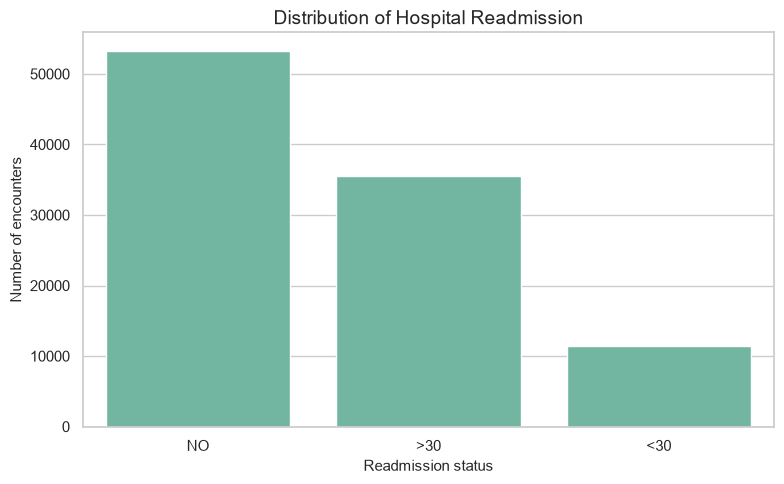

,Count,Percentage
readmitted,,
NO,53212,53.15
>30,35545,35.50
<30,11357,11.34


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

readmission_order = ["NO", ">30", "<30"]

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="readmitted", order=readmission_order)
plt.title("Distribution of Hospital Readmission")
plt.xlabel("Readmission status")
plt.ylabel("Number of encounters")
plt.tight_layout()
plt.show()

readmission_summary = (
    df["readmitted"].value_counts()
      .reindex(readmission_order)
      .rename("Count")
      .to_frame()
)
readmission_summary["Percentage"] = (
    readmission_summary["Count"] / len(df) * 100
).round(2)
display(readmission_summary)

Time in Hospital vs. Number of Lab Procedures (Scatter Plot)

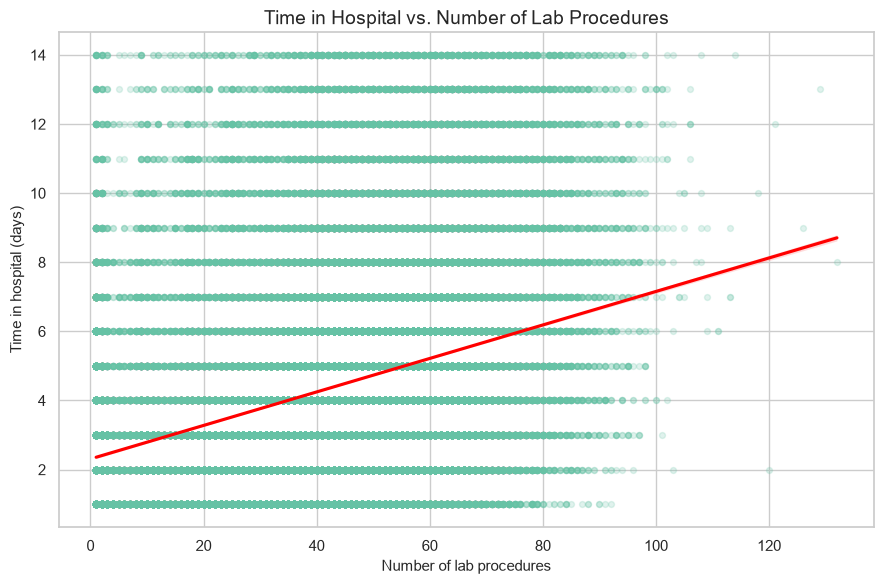

Pearson correlation: 0.32


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))
sns.regplot(
    data=df,
    x="num_lab_procedures",
    y="time_in_hospital",
    scatter_kws={"alpha": 0.2, "s": 18},
    line_kws={"color": "red"}
)
plt.title("Time in Hospital vs. Number of Lab Procedures")
plt.xlabel("Number of lab procedures")
plt.ylabel("Time in hospital (days)")
plt.tight_layout()
plt.show()

print(
    "Pearson correlation:",
    round(df[["num_lab_procedures", "time_in_hospital"]].corr().iloc[0, 1], 3)
)

Numerical Features Correlation (Heatmap)

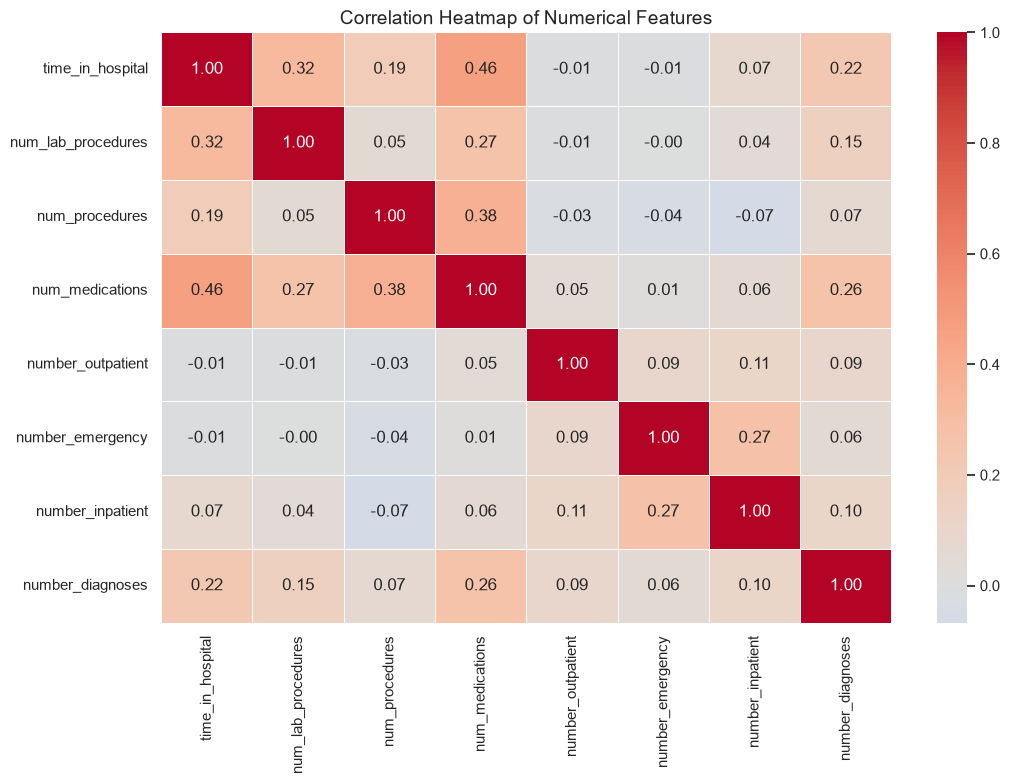

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

correlation_matrix = df[numeric_features].corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

Hospital Stay by Readmission Status (Box Plot)

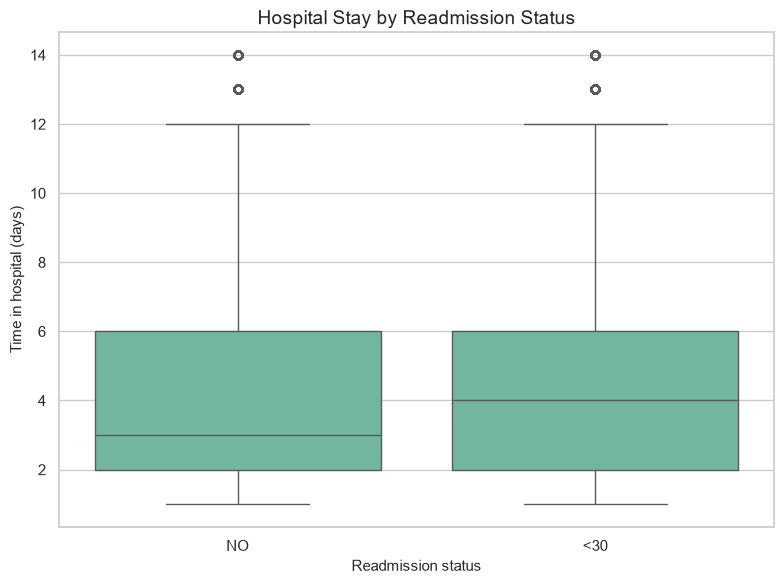

,count,mean,std,min,25%,50%,75%,max
readmitted,,,,,,,,
<30,11357.0,4.77,3.03,1.0,2.0,4.0,6.0,14.0
NO,53212.0,4.24,2.94,1.0,2.0,3.0,6.0,14.0


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

box_data = df[df["readmitted"].isin(["NO", "<30"])].copy()

plt.figure(figsize=(8, 6))
sns.boxplot(
    data=box_data,
    x="readmitted",
    y="time_in_hospital",
    order=["NO", "<30"]
)
plt.title("Hospital Stay by Readmission Status")
plt.xlabel("Readmission status")
plt.ylabel("Time in hospital (days)")
plt.tight_layout()
plt.show()

display(
    box_data.groupby("readmitted")["time_in_hospital"]
            .describe()
            .round(2)
)

Readmission by Discharge Disposition (Grouped Bar Chart)

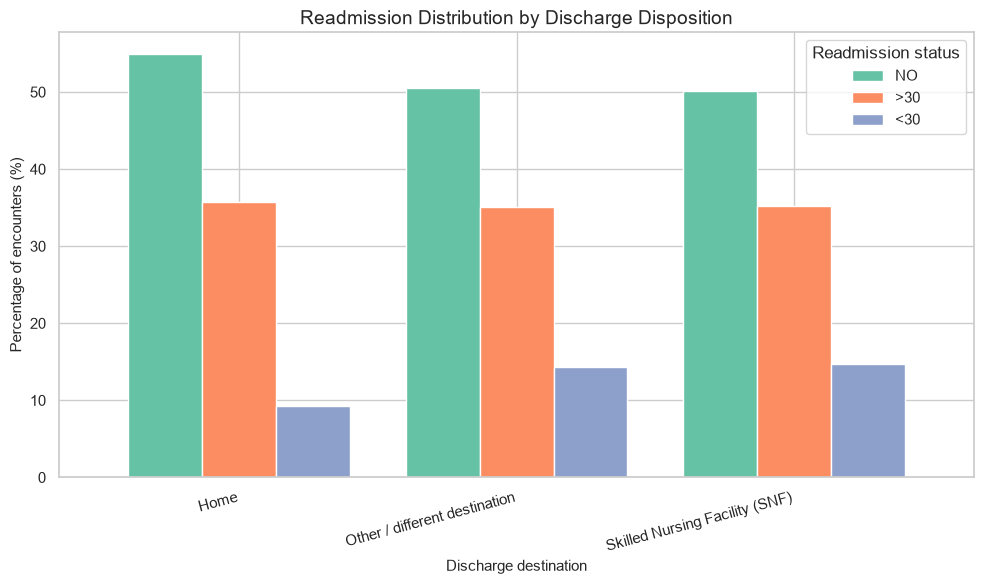

readmitted,NO,>30,<30
discharge_group,,,
Home,54.98,35.72,9.30
Other / different destination,50.55,35.15,14.31
Skilled Nursing Facility (SNF),50.11,35.23,14.66


discharge_group
Home                               9.30
Skilled Nursing Facility (SNF)    14.66
Name: Readmission within 30 days (%), dtype: float64

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

disposition_map = {
    1: "Home",
    3: "Skilled Nursing Facility (SNF)"
}

df["discharge_group"] = (
    pd.to_numeric(df["discharge_disposition_id"], errors="coerce")
      .map(disposition_map)
      .fillna("Other / different destination")
)

discharge_distribution = (
    pd.crosstab(df["discharge_group"], df["readmitted"], normalize="index")
      .reindex(columns=readmission_order)
      .mul(100)
)

ax = discharge_distribution.plot(kind="bar", figsize=(10, 6), width=0.8)
ax.set_title("Readmission Distribution by Discharge Disposition")
ax.set_xlabel("Discharge destination")
ax.set_ylabel("Percentage of encounters (%)")
ax.legend(title="Readmission status")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

display(discharge_distribution.round(2))

early_by_discharge = (
    df[df["discharge_group"].isin(["Home", "Skilled Nursing Facility (SNF)"])]
      .assign(early_readmission=lambda x: (x["readmitted"] == "<30").astype(int))
      .groupby("discharge_group")["early_readmission"]
      .mean()
      .mul(100)
      .round(2)
      .rename("Readmission within 30 days (%)")
)
display(early_by_discharge)

Demographic Profiling - by Age Group

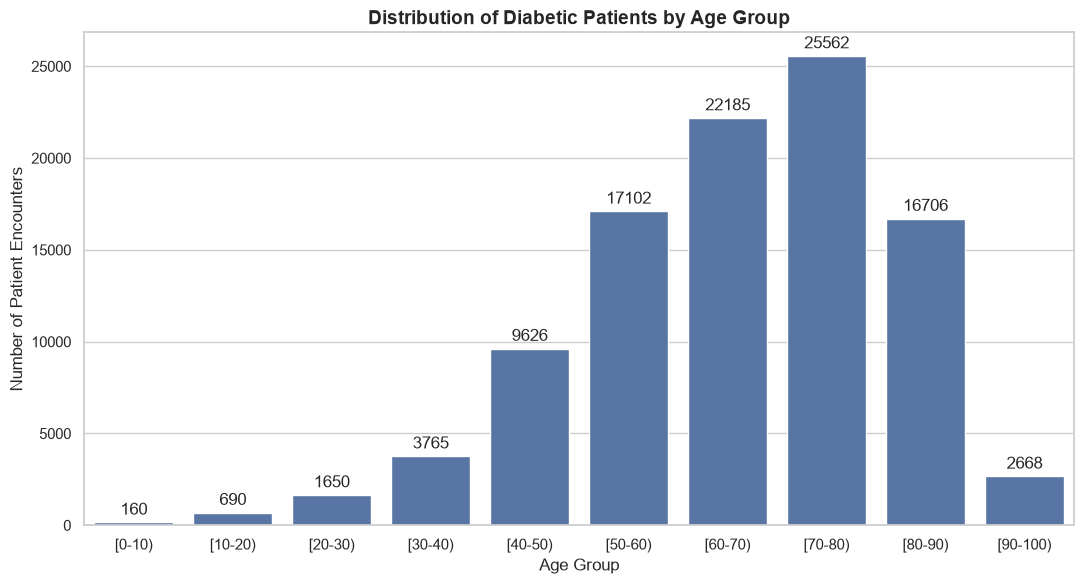

,Patient Count,Percentage (%)
age,,
[0-10),160,0.16
[10-20),690,0.69
[20-30),1650,1.65
[30-40),3765,3.76
[40-50),9626,9.62
[50-60),17102,17.08
[60-70),22185,22.16
[70-80),25562,25.53
[80-90),16706,16.69


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))

ax = sns.countplot(data=df, x='age', order=sorted(df['age'].dropna().unique()))

plt.title("Distribution of Diabetic Patients by Age Group",fontsize=14, fontweight="bold")

plt.xlabel("Age Group")
plt.ylabel("Number of Patient Encounters")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

# Display age distribution summary
age_counts = df['age'].value_counts().sort_index()

age_summary = pd.DataFrame({
    "Patient Count": age_counts,
    "Percentage (%)": (age_counts / len(df) * 100).round(2)
})

display(age_summary)

Demographic Profiling - by Race and Gender